# CA1 Twist 3: Distracted Pedestrian Detection, Model Training

Adapted from the Lesson 3 training notebook. The pipeline, cell order and helper
functions are unchanged; only the configuration, class handling, paths and notes
were updated for the CA1 Twist 3 project. Run the cells top to bottom.

## What this notebook builds

A YOLO26 model fine tuned on four classes, trained on our team's Roboflow
dataset, then wrapped in code that reports a per image count for each class:

| Class ID | Class name          | Meaning                                                |
|----------|---------------------|--------------------------------------------------------|
| 0        | `person_left`       | pedestrian walking towards the left                    |
| 1        | `person_right`      | pedestrian walking towards the right                   |
| 2        | `phone_using_left`  | pedestrian walking left while using a phone (distracted)  |
| 3        | `phone_using_right` | pedestrian walking right while using a phone (distracted) |

Classes 0 and 1 keep the baseline People Counting Assistant behaviour. Classes 2
and 3 are the Twist 3 addition: a distracted pedestrian is detected directly as
`phone_using_left` or `phone_using_right`, so the direction is kept for
distracted pedestrians too.

## Pipeline

1. Setup: installs, GPU check, Drive folders isolated under `CA1_Twist3`
2. Dataset: Roboflow download, 4-class check, `data.yaml` fix, split counts
3. Pretrained baseline: what a stock COCO model reports
4. Training configuration: hyperparameters and the `fliplr=0.0` rule
5. Training, followed by the train vs. validation loss plots
6. Per class results and Ultralytics curves
7. Error review against the annotations
8. Counting per class with a confidence threshold
9. Export of `best.pt` and metrics to `artifacts/CA1_Twist3/`

Every detection is read from a single frame. There is no tracking in this notebook.

---

## 1. Setup

Two installs and a GPU check. Ultralytics is pinned to the same version as the
Lesson 3 baseline, so the Twist 3 results can be compared with the baseline run
without a library change muddying the comparison. Use a T4 GPU runtime in Colab.

In [ ]:
# Pinned, so every team trains on the same code.
ULTRALYTICS_VERSION = "8.4.120"

try:
    import google.colab  # noqa: F401
    RUNNING_ON_COLAB = True
except ImportError:
    RUNNING_ON_COLAB = False

if RUNNING_ON_COLAB:
    import subprocess
    # roboflow is left unpinned on purpose. It talks to a hosted service, so the
    # version that matches the service is whichever one is current.
    subprocess.run(
        ["pip", "install", "-q", "ultralytics==" + ULTRALYTICS_VERSION, "roboflow"],
        check=True,
    )

print("Running on Colab:", RUNNING_ON_COLAB)

Running on Colab: True


In [ ]:
import json
import os
import random

import torch
from ultralytics import YOLO

print("torch    :", torch.__version__)
print("GPU      :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

if not torch.cuda.is_available():
    print("")
    print("No GPU. In Colab: Runtime, Change runtime type, T4 GPU.")
    print("Training on CPU works but takes far longer than the lab allows.")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
torch    : 2.11.0+cu130
GPU      : Tesla T4


### Where the work is kept

Everything is written to Drive so that closing the runtime does not lose the
trained weights. Twist 3 uses its own folder, `runs/CA1_Twist3`, so the Lesson 3
baseline run under `runs/L3` is never overwritten.

In [ ]:
if RUNNING_ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/C389"
    # Twist 3 outputs are kept apart from the Lesson 3 baseline (runs/L3).
    WORK_DIR = "/content/drive/MyDrive/C389/runs/CA1_Twist3_Organised"
else:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
    WORK_DIR = os.path.join(PROJECT_ROOT, "runs", "CA1_Twist3_Organised")

os.makedirs(WORK_DIR, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("WORK_DIR    :", WORK_DIR)

Mounted at /content/drive
PROJECT_ROOT: /content/drive/MyDrive/C389
WORK_DIR    : /content/drive/MyDrive/C389/runs/CA1_Twist3_Organised


---

## 2. The dataset, from Roboflow

The Twist 3 dataset is our team's Roboflow project, annotated with the four
classes `person_left`, `person_right`, `phone_using_left` and
`phone_using_right`. The train / valid / test split
is the one Roboflow made when the version was generated, used as it is.

- `ROBOFLOW_CODE` holds the download snippet from Roboflow (**Download Dataset**,
  YOLOv8 or YOLO26 format, **Show download code**). Both formats write the same
  label layout: one text file per image with normalised boxes.
- The API key is **not** stored in the notebook, because the notebook is pushed
  to the team repository. The line must read `api_key=""`. The cell reads the key
  from Colab **Secrets** (`ROBOFLOW_API_KEY`) or asks for it in a hidden prompt,
  and stops if a key was left in the pasted code.
- If `ROBOFLOW_CODE` is empty, the cell falls back to the drawn sample set, which
  only proves the pipeline runs. Its numbers say nothing about the real problem.

In [ ]:
import re
from getpass import getpass

# Paste the download code from Roboflow between the triple quotes, then delete the
# key so the line reads api_key="". Leave it empty to use the sample set.
ROBOFLOW_CODE = """
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="")
project = rf.workspace("c389team3").project("c389_ca1")
version = project.version(10)
dataset = version.download("yolo26")



"""

SAMPLE_DIR = os.path.join(PROJECT_ROOT, "data", "sample", "walkway")
YOLO_FORMATS = ("yolov8", "yolo26", "yolov11", "yolov12", "yolov9", "yolov5")


def read_roboflow_code(code):
    """Read the workspace, project, version and format out of Roboflow's code.

    Returns None when nothing was pasted. Raises ValueError when the code still
    holds the private key, or lacks a value the download needs.
    """
    if not code.strip():
        return None
    key = re.search(r"api_key\s*=\s*[\"']([^\"']*)[\"']", code)
    if key and key.group(1).strip():
        raise ValueError(
            "The pasted code still holds your private API key. Delete it so the "
            "line reads api_key=\"\", then run the cell again. The key is asked "
            "for when the cell runs, so it is never saved in the notebook.")
    found = {}
    for name, pattern in (("workspace", r"\.workspace\(\s*[\"']([^\"']+)[\"']"),
                          ("project", r"\.project\(\s*[\"']([^\"']+)[\"']"),
                          ("version", r"\.version\(\s*(\d+)\s*\)"),
                          ("format", r"\.download\(\s*[\"']([^\"']+)[\"']")):
        match = re.search(pattern, code)
        if not match:
            raise ValueError(
                "No %s in the pasted code. Copy the whole block Roboflow shows "
                "under Show download code." % name)
        found[name] = match.group(1)
    found["version"] = int(found["version"])
    # YOLOv8, YOLO26 and the other YOLO text formats write the same files: one
    # label file per image and a data.yaml. Anything else is a different layout.
    if found["format"] not in YOLO_FORMATS:
        raise ValueError(
            "The code downloads the %r format. Choose YOLOv8 in the Download "
            "Dataset window and copy the code again." % found["format"])
    return found


def roboflow_key():
    """The private key from Colab Secrets, or else from a hidden prompt."""
    if RUNNING_ON_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("ROBOFLOW_API_KEY").strip()
        except Exception:
            pass  # no secret saved, or this notebook is not allowed to read it
    return getpass("Roboflow private API key: ").strip()


ROBOFLOW = read_roboflow_code(ROBOFLOW_CODE)

if ROBOFLOW:
    from roboflow import Roboflow

    print("workspace %(workspace)s, project %(project)s, version %(version)d" % ROBOFLOW)
    project = Roboflow(api_key=roboflow_key()).workspace(
        ROBOFLOW["workspace"]).project(ROBOFLOW["project"])
    export = project.version(ROBOFLOW["version"]).download(
        ROBOFLOW["format"], location=os.path.join(WORK_DIR, "dataset"), overwrite=True
    )
    DATASET_DIR = export.location
    USING_SAMPLE_DATA = False
else:
    if not os.path.isdir(SAMPLE_DIR):
        raise FileNotFoundError(
            "Nothing was pasted and there is no sample set at %s.\n"
            "Paste the Roboflow download code, or run scripts/make_sample_data.py."
            % SAMPLE_DIR
        )
    DATASET_DIR = SAMPLE_DIR
    USING_SAMPLE_DATA = True

DATA_YAML = os.path.join(DATASET_DIR, "data.yaml")
print("dataset:", DATASET_DIR)

if USING_SAMPLE_DATA:
    print("")
    print("WARNING: using the drawn sample set. It checks that the pipeline runs.")
    print("Every number below is meaningless about the real problem.")


workspace c389team3, project c389_ca1, version 10
Roboflow private API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/drive/MyDrive/C389/runs/CA1_Twist3_Organised/dataset in yolo26:: 100%|██████████| 1231/1231 [00:10<00:00, 121.82it/s]

dataset: /content/drive/MyDrive/C389/runs/CA1_Twist3_Organised/dataset


### The class list

The class list is read from `data.yaml`, then checked against the Twist 3 order:

- ID 0 `person_left`, ID 1 `person_right`: unchanged from the baseline. Class IDs
  are positional, and Lessons 4 and 5 read the two directions by position, so
  these two must stay at 0 and 1.
- ID 2 `phone_using_left`, ID 3 `phone_using_right`: the Twist 3 classes,
  appended after the direction classes so the baseline IDs do not shift.

If the check fails, fix the class order in Roboflow and export again.

In [ ]:
def read_class_names(yaml_path):
    """Read the ordered class list out of a Roboflow data.yaml.

    Parsed by hand rather than with pyyaml, because the one line that matters is
    a plain list and a dependency for it is not worth the install.
    """
    with open(yaml_path, encoding="utf-8") as handle:
        for line in handle:
            if line.startswith("names:"):
                body = line.split(":", 1)[1].strip().strip("[]")
                return [name.strip().strip("'\"") for name in body.split(",")]
    raise ValueError("No names: line in %s" % yaml_path)


CLASS_NAMES = read_class_names(DATA_YAML)
print("classes:", CLASS_NAMES)

# CA1 Twist 3 updated class order: 0 person_left, 1 person_right, 2 phone_using_left, 3 phone_using_right.
EXPECTED_CLASSES = ["person_left", "person_right", "phone_using_left", "phone_using_right"]

EXPECTED_FIRST_TWO = EXPECTED_CLASSES[:2]
if CLASS_NAMES[:2] != EXPECTED_FIRST_TWO:
    raise ValueError(
        "The first two classes are %s and must be %s, in that order.\n"
        "Lessons 4 and 5 read the classes by position, so a different order "
        "counts the wrong direction. Fix the class names in Roboflow and export again."
        % (CLASS_NAMES[:2], EXPECTED_FIRST_TWO)
    )

# The drawn sample set only has the two direction classes, so the full check
# applies to the real Roboflow export only.
if CLASS_NAMES != EXPECTED_CLASSES and not USING_SAMPLE_DATA:
    raise ValueError(
        "The classes are %s and must be exactly %s for Twist 3.\n"
        "The phone classes must be appended after the two direction classes in the correct order. "
        "Fix the class list in Roboflow and export again." % (CLASS_NAMES, EXPECTED_CLASSES)
    )

classes: ['person_left', 'person_right', 'phone_using_left', 'phone_using_right']


### Making the dataset path unambiguous

A Roboflow export writes its split paths as `../train/images`. Those are
resolved against the folder the file sits in, so the `..` climbs one level too
high and training stops with a dataset-not-found error naming a path nobody
typed.

The cell below rewrites the file with an absolute `path:` and plain split names.
Nothing about the data changes. It is here because this is the single most common
way a first Colab run fails, and the error message does not say what to do.

In [ ]:
def normalise_data_yaml(dataset_dir):
    """Rewrite data.yaml with an absolute path, keeping the class list.

    Returns the path to the file that was written.
    """
    yaml_path = os.path.join(dataset_dir, "data.yaml")
    names_line = None
    with open(yaml_path, encoding="utf-8") as handle:
        for line in handle:
            if line.startswith("names:"):
                names_line = line.rstrip()

    if names_line is None:
        raise ValueError("No names: line in %s" % yaml_path)

    splits = []
    for key, folder in (("train", "train"), ("val", "valid"), ("test", "test")):
        if os.path.isdir(os.path.join(dataset_dir, folder, "images")):
            splits.append("%s: %s/images" % (key, folder))

    if not any(line.startswith("train:") for line in splits):
        raise FileNotFoundError(
            "No train/images folder under %s. The export did not unpack the way "
            "this notebook expects." % dataset_dir)

    class_count = len(read_class_names(yaml_path))
    with open(yaml_path, "w", encoding="utf-8") as handle:
        print("# Paths rewritten by this notebook so that they resolve from",
              "anywhere.", file=handle)
        print("path:", dataset_dir.replace(os.sep, "/"), file=handle)
        for line in splits:
            print(line, file=handle)
        print("", file=handle)
        print("nc:", class_count, file=handle)
        print(names_line, file=handle)
    return yaml_path


normalise_data_yaml(DATASET_DIR)
print(open(DATA_YAML, encoding="utf-8").read())

# Paths rewritten by this notebook so that they resolve from anywhere.
path: /content/drive/MyDrive/C389/runs/CA1_Twist3_Organised/dataset
train: train/images
val: valid/images
test: test/images

nc: 4
names: ['person_left', 'person_right', 'phone_using_left', 'phone_using_right']



### The split Roboflow made

Roboflow put each image in one of three folders when the version was generated:
`train` is what the model learns from, `valid` is what it is checked against while
it trains, and `test` is kept back for the final score in Section 6.

The cell below counts what landed where. A version generated with no test images
still works: the notebook then reports its final score on `valid` and says so.

In [ ]:
SPLIT_FOLDERS = ["train", "valid", "test"]


def count_images(dataset_dir, split):
    """How many images one split folder holds, 0 when the folder is missing."""
    image_dir = os.path.join(dataset_dir, split, "images")
    if not os.path.isdir(image_dir):
        return 0
    return sum(1 for name in os.listdir(image_dir)
               if name.lower().endswith((".jpg", ".jpeg", ".png")))


SPLIT_COUNTS = {split: count_images(DATASET_DIR, split) for split in SPLIT_FOLDERS}
for split in SPLIT_FOLDERS:
    print("%-6s %4d images" % (split, SPLIT_COUNTS[split]))

if not SPLIT_COUNTS["train"]:
    raise ValueError("The version has no training images. Generate it again in "
                     "Roboflow with images in Train.")

# The split every result below is judged on. Ultralytics calls the valid folder "val".
EVAL_FOLDER = "test" if SPLIT_COUNTS["test"] else "valid"
EVAL_SPLIT = "test" if EVAL_FOLDER == "test" else "val"
if EVAL_FOLDER == "valid":
    print("")
    print("No test images, so the final score is read on valid instead.")

train   617 images
valid   174 images
test    167 images


---

## 3. What a pretrained model cannot tell you

The stock `yolo26n.pt` model is trained on COCO. COCO has `person` and
`cell phone` classes but nothing direction aware, so it cannot produce
`person_left` or `person_right`.

Two images are run: `bus.jpg` from Ultralytics and one image from our dataset.
The `to_detections()` helper defined here converts a result into plain
dictionaries and is reused for all three Twist 3 classes later on.

In [ ]:
def image_paths(dataset_dir, split, limit=None):
    """List the images in one split, in filename order."""
    image_dir = os.path.join(dataset_dir, split, "images")
    names = sorted(name for name in os.listdir(image_dir)
                   if name.lower().endswith((".jpg", ".jpeg", ".png")))
    if limit:
        names = names[:limit]
    return [os.path.join(image_dir, name) for name in names]


def to_detections(result, class_names):
    """Turn one Ultralytics result into plain dictionaries.

    Works for any ordered class list. For Twist 3 that is
    0 person_left, 1 person_right, 2 phone, so phone detections come out
    with class_name "phone" alongside the two direction classes.

    The same shape is used in the service in Lesson 4, so the counting code
    written below is the code that ships.
    """
    detections = []
    boxes = result.boxes
    if boxes is None:
        return detections
    for index in range(len(boxes)):
        class_id = int(boxes.cls[index].item())
        # Any ID outside the class list is kept as its number rather than
        # dropped, so a class mismatch is visible instead of silent.
        name = class_names[class_id] if 0 <= class_id < len(class_names) else str(class_id)
        detections.append({
            "class_name": name,
            "confidence": round(float(boxes.conf[index].item()), 3),
            "box": [round(float(value), 1) for value in boxes.xyxy[index].tolist()],
        })
    return detections


from ultralytics.utils import ASSETS

BASELINE_MODEL = "yolo26n.pt"
pretrained = YOLO(BASELINE_MODEL)
pretrained_names = [pretrained.names[key] for key in sorted(pretrained.names)]

# A real photograph first, then one image from this dataset. The photograph is
# what carries the point, and it is here because a model trained on photographs
# has never seen a drawing and reports nothing on the sample set.
baseline_paths = [os.path.join(str(ASSETS), "bus.jpg")]
baseline_paths += image_paths(DATASET_DIR, EVAL_FOLDER, limit=1)

for path in baseline_paths:
    result = pretrained.predict(path, conf=0.35, verbose=False)[0]
    detections = to_detections(result, pretrained_names)
    print(os.path.basename(path))
    for detection in detections:
        print("   %-12s %.2f" % (detection["class_name"], detection["confidence"]))
    if not detections:
        print("   nothing detected")

bus.jpg
   bus          0.92
   person       0.91
   person       0.91
   person       0.87
   person       0.53
2026-10-27-00-45-56_png.rf.111a527b64b5baece003935241a4e6b6.jpg
   person       0.90
   person       0.89
   person       0.86
   person       0.83
   person       0.68
   person       0.63
   person       0.58
   person       0.56
   person       0.45
   person       0.42
   person       0.37


**Observation.** The stock model labels every pedestrian `person`. It finds
people, but it cannot tell left from right, because it was never trained to.
COCO's `cell phone` class can find phones, but it uses COCO's class IDs, has no
link to our direction classes, and was not trained on phones held by
pedestrians in our scenes.

This is the justification for fine tuning: Twist 3 needs `person_left`,
`person_right` and `phone` as one consistent 3-class output, and no threshold,
image size or larger variant of the stock model produces that.

On the drawn sample images the stock model reports nothing at all, because a
model trained on photographs does not recognise line drawings.

---

## 4. Training configuration

### Hyperparameters and rationale

| Setting | Value | Reason |
|---------|-------|--------|
| `MODEL_VARIANT` | `yolo26n.pt` | Nano variant: fast to train on a Colab T4 and light enough to serve in Lesson 4. Same as the baseline, so differences come from the data and the new class. |
| `EPOCHS` | `100` | The dataset is small, so each epoch gives only a few optimiser steps. 100 epochs gives the model enough steps to become confident; the loss plots after training show whether that was too many or too few. |
| `IMAGE_SIZE` | `640` | YOLO's native size. Phones are small objects, and a smaller size would shrink them to a few pixels. |
| `BATCH_SIZE` | `16` | Fits in T4 memory at 640. Reduce this first if the run fails out of memory. |
| `FLIP_LEFT_RIGHT` (`fliplr`) | `0.0` | **Fixed, not tunable.** See below. |

### Why horizontal flipping is disabled

Horizontal flip augmentation mirrors an image but keeps its labels. A mirrored
`person_left` is visually a person walking right while still labelled
`person_left`, which teaches the model the opposite of the truth on part of the
data. The training curves would look normal, so the damage would not show.
`fliplr` therefore stays at `0.0`, and the configuration cell refuses to continue
if it is changed. Flipping would not hurt `phone`, but augmentation applies to
the whole image, so it cannot be enabled for one class only.

### Optimiser steps

The model learns from optimiser steps: training images / batch size x epochs.
The next cell prints this number. Too few steps gives a model that roughly
localises objects but is never confident, which shows up as zero counts in
Section 8.

In [ ]:
# CA1 Twist 3 training configuration (rationale in the markdown above).
MODEL_VARIANT = "yolo26n.pt"
EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 16

In [ ]:
# fliplr must stay at 0.0.
#
# Horizontal flip augmentation mirrors the image and keeps the original label. A
# flipped person_left is a person moving right, still labelled person_left, so
# the model is taught the opposite of the truth on half the data. Nothing in the
# output reveals it: the curves look normal and the score looks reasonable. This
# is the one setting in this notebook that is not a choice.
FLIP_LEFT_RIGHT = 0.0
if FLIP_LEFT_RIGHT != 0.0:
    raise ValueError("FLIP_LEFT_RIGHT must be 0.0: flipping reverses the "
                     "person_left / person_right labels.")

missing = [name for name, value in (
    ("MODEL_VARIANT", MODEL_VARIANT), ("EPOCHS", EPOCHS),
    ("IMAGE_SIZE", IMAGE_SIZE), ("BATCH_SIZE", BATCH_SIZE)) if value is None]
if missing:
    raise ValueError("Set these before launching: %s" % ", ".join(missing))

training_images = len(image_paths(DATASET_DIR, "train"))
steps_per_epoch = max(1, training_images // BATCH_SIZE)
total_steps = steps_per_epoch * EPOCHS

print("model variant :", MODEL_VARIANT)
print("epochs        :", EPOCHS)
print("image size    :", IMAGE_SIZE)
print("batch size    :", BATCH_SIZE)
print("fliplr        :", FLIP_LEFT_RIGHT, "(must be 0.0)")
print("")
print("training images  : %d" % training_images)
print("optimiser steps  : %d per epoch, %d in total" % (steps_per_epoch, total_steps))

if total_steps < 300:
    print("")
    print("That is a small number of steps. Expect a model that finds roughly the")
    print("right places and is not confident about any of them, which shows up as")
    print("counts of zero in Section 8. Raise the epochs rather than the threshold.")

model variant : yolo26n.pt
epochs        : 100
image size    : 640
batch size    : 16
fliplr        : 0.0 (must be 0.0)

training images  : 617
optimiser steps  : 38 per epoch, 3800 in total


---

## 5. Training

One `model.train()` call with the Section 4 configuration. Each launch is written
to the next free run folder directly under `WORK_DIR` (`run1`, `run2`, `run3`, ...),
so an earlier run is never overwritten. `RUN_DIR` and `BEST_WEIGHTS` are set from
that folder and every later section reads them, so the cells below always refer
to the run that was just trained.

`fliplr=FLIP_LEFT_RIGHT` is passed explicitly so the Ultralytics default of 0.5
never applies, and `seed=0` keeps the run repeatable.

The cell after training reads `results.csv` from `RUN_DIR` and plots training
against validation loss, for the overfitting / underfitting discussion in the
CA1 report.

In [ ]:
# The next free run folder directly under WORK_DIR: run1, run2, run3, ...
run_index = 1
while os.path.exists(os.path.join(WORK_DIR, "run%d" % run_index)):
    run_index += 1
TRAIN_RUN_NAME = "run%d" % run_index

RUN_DIR = os.path.join(WORK_DIR, TRAIN_RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("training into:", RUN_DIR)

model = YOLO(MODEL_VARIANT)

results = model.train(
    data=DATA_YAML,
    epochs=100,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,

    # MUST stay 0.0 for direction learning
    fliplr=0.0,

    optimizer="AdamW",

    project=WORK_DIR,
    name=TRAIN_RUN_NAME,
    exist_ok=True,
    seed=0,
    lr0=0.001,          # was the default 0.01, too high for AdamW
    cos_lr=True,        # optional: smoother decay; remove it to change only lr0
)

if not os.path.exists(BEST_WEIGHTS):
    raise FileNotFoundError(
        "No best.pt at %s. Ultralytics wrote this run to %s instead."
        % (BEST_WEIGHTS, model.trainer.save_dir))
print("")
print("weights:", BEST_WEIGHTS)

training into: /content/drive/MyDrive/C389/runs/CA1_Twist3_Organised/run7
New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.120 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/drive/MyDrive/C389/runs/CA1_Twist3_Organised/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, io

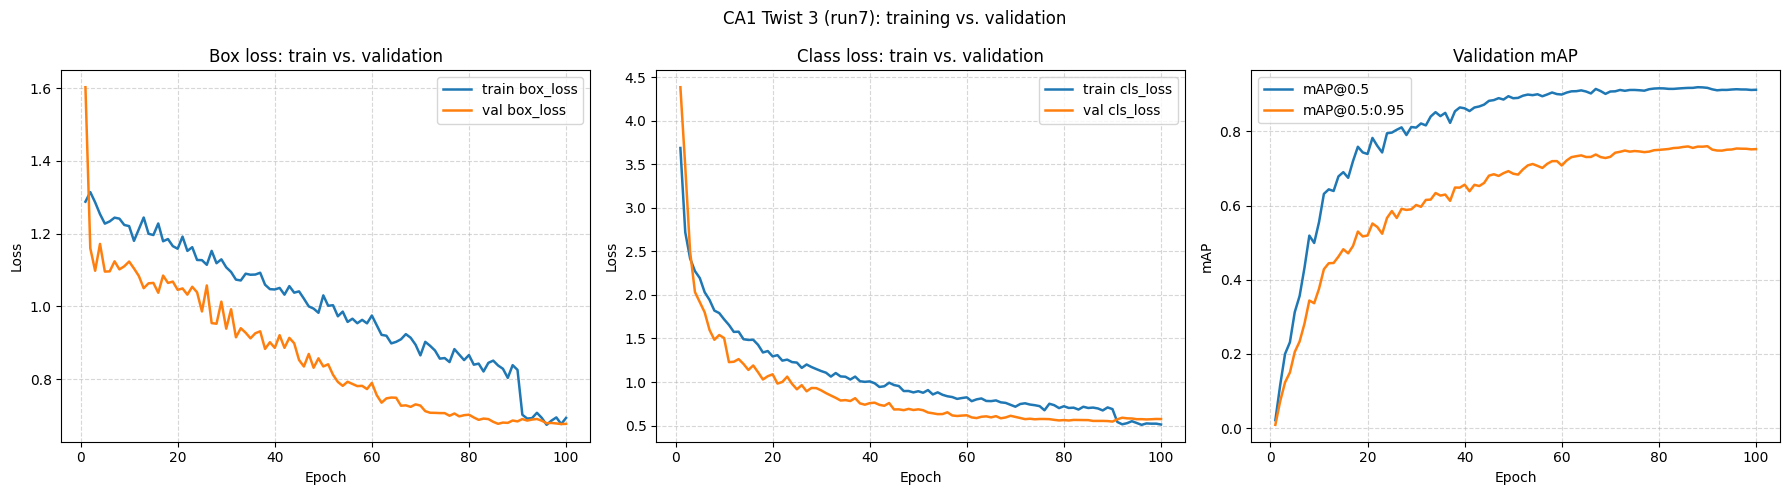

plot saved to /content/drive/MyDrive/C389/runs/CA1_Twist3_Organised/run7/twist3_train_vs_val.png

final epoch : train box 0.694  val box 0.677  train cls 0.512  val cls 0.575
best epoch  : 90  (mAP@0.5 0.917, mAP@0.5:0.95 0.760)


In [ ]:
# Train vs. validation curves for the CA1 report, read from results.csv.
import matplotlib.pyplot as plt
import pandas as pd
import os

RESULTS_CSV = os.path.join(RUN_DIR, "results.csv")
history = pd.read_csv(RESULTS_CSV)
history.columns = [column.strip() for column in history.columns]
epochs_axis = history["epoch"] if "epoch" in history.columns else history.index + 1

PANELS = [
    ("Box loss: train vs. validation", "Loss",
     [("train/box_loss", "train box_loss"), ("val/box_loss", "val box_loss")]),
    ("Class loss: train vs. validation", "Loss",
     [("train/cls_loss", "train cls_loss"), ("val/cls_loss", "val cls_loss")]),
    ("Validation mAP", "mAP",
     [("metrics/mAP50(B)", "mAP@0.5"), ("metrics/mAP50-95(B)", "mAP@0.5:0.95")]),
]

figure, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, (title, y_label, series) in zip(axes, PANELS):
    for column, label in series:
        if column in history.columns:
            axis.plot(epochs_axis, history[column], label=label, linewidth=1.8)
        else:
            print("column not found in results.csv:", column)
    axis.set_title(title)
    axis.set_xlabel("Epoch")
    axis.set_ylabel(y_label)
    axis.grid(True, linestyle="--", alpha=0.5)
    axis.legend()

figure.suptitle("CA1 Twist 3 (%s): training vs. validation" % TRAIN_RUN_NAME)
figure.tight_layout()
LOSS_PLOT_PATH = os.path.join(RUN_DIR, "twist3_train_vs_val.png")
figure.savefig(LOSS_PLOT_PATH, dpi=150)
plt.show()
print("plot saved to", LOSS_PLOT_PATH)

last = history.iloc[-1]
best_row = history.loc[history["metrics/mAP50-95(B)"].idxmax()] if "metrics/mAP50-95(B)" in history.columns else last
print("\nfinal epoch : train box %.3f  val box %.3f  train cls %.3f  val cls %.3f"
      % (last.get("train/box_loss", float("nan")), last.get("val/box_loss", float("nan")),
         last.get("train/cls_loss", float("nan")), last.get("val/cls_loss", float("nan"))))
print("best epoch  : %d  (mAP@0.5 %.3f, mAP@0.5:0.95 %.3f)"
      % (int(best_row.get("epoch", len(history))),
         best_row.get("metrics/mAP50(B)", float("nan")),
         best_row.get("metrics/mAP50-95(B)", float("nan"))))

---

## 6. Reading the result

Scores are reported per class for `person_left`, `person_right` and `phone`,
never only as the overall mean. The mean can hide one class learned much worse
than the others. `phone` is the most likely weak class, because phones are small
and often partly covered by a hand. A wide gap usually points at class imbalance
or inconsistent annotation rather than at the model.

In [ ]:
trained = YOLO(BEST_WEIGHTS)

# Safeguard class names dictionary mapping
trained.model.names = {i: name for i, name in enumerate(CLASS_NAMES)}

metrics = trained.val(data=DATA_YAML, split=EVAL_SPLIT, verbose=False)

# Overall mAP@0.5 on the evaluation split. Section 9 compares this number with
# the exported model to decide whether this run replaces it.
EVAL_MAP50 = float(metrics.box.map50)
print("run: %s   overall mAP@.5 on %s: %.3f" % (TRAIN_RUN_NAME, EVAL_FOLDER, EVAL_MAP50))
print("")

# --- Log overall and per class metrics to the master experiments_summary.csv ---
from datetime import datetime
import pandas as pd

SUMMARY_CSV = os.path.join(PROJECT_ROOT, "experiments_summary.csv")
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M")

# Ultralytics' val() result does not carry the epoch number, so the best epoch is
# read from this run's results.csv: the epoch with the highest metrics/mAP50(B).
run_history = pd.read_csv(os.path.join(RUN_DIR, "results.csv"))
run_history.columns = [column.strip() for column in run_history.columns]
peak_row = run_history.loc[run_history["metrics/mAP50(B)"].idxmax()]
best_epoch = (int(peak_row["epoch"]) if "epoch" in run_history.columns
              else int(peak_row.name) + 1)

# 1. Overall run summary, on the evaluation split
summary_data = {
    "Run Folder": TRAIN_RUN_NAME,
    "Best Epoch": best_epoch,
    "Overall_Precision": round(float(metrics.box.mp), 4),
    "Overall_Recall": round(float(metrics.box.mr), 4),
    "Overall_mAP50": round(float(metrics.box.map50), 4),
    "Overall_mAP50-95": round(float(metrics.box.map), 4),
    "Date/Timestamp": TIMESTAMP,
}

# 2. Per class summary. Every class in CLASS_NAMES gets its four columns, left
# empty (NaN) when the split has no instances of it, so every row has the same
# columns and appended rows stay aligned with the header.
per_class_scores = {}
for index, class_id in enumerate(metrics.ap_class_index):
    class_idx = int(class_id)
    if class_idx < len(CLASS_NAMES):
        per_class_scores[CLASS_NAMES[class_idx]] = (
            float(metrics.box.p[index]), float(metrics.box.r[index]),
            float(metrics.box.ap50[index]), float(metrics.box.ap[index]))
for c_name in CLASS_NAMES:
    p, r, ap50, ap = per_class_scores.get(c_name, (float("nan"),) * 4)
    summary_data[f"Precision_{c_name}"] = round(p, 4)
    summary_data[f"Recall_{c_name}"] = round(r, 4)
    summary_data[f"mAP50_{c_name}"] = round(ap50, 4)
    summary_data[f"mAP50-95_{c_name}"] = round(ap, 4)

# 3. Append the row: header the first time, mode="a" after that.
summary_df = pd.DataFrame([summary_data])
already_logged = False
if os.path.exists(SUMMARY_CSV):
    logged = pd.read_csv(SUMMARY_CSV)
    if list(logged.columns) != list(summary_df.columns):
        raise ValueError(
            "%s has the columns %s, not %s. It was written by an older version of "
            "this cell. Rename or move it, then run this cell again."
            % (SUMMARY_CSV, list(logged.columns), list(summary_df.columns)))
    # Running this cell twice for the same run would log it twice.
    already_logged = ((logged["Run Folder"] == TRAIN_RUN_NAME)
                      & (logged["Best Epoch"] == best_epoch)).any()

if already_logged:
    print(f"{TRAIN_RUN_NAME} is already in {SUMMARY_CSV}, not appended again.")
else:
    write_header = not os.path.exists(SUMMARY_CSV)
    summary_df.to_csv(SUMMARY_CSV, mode="a", header=write_header, index=False)
    print(f"✅ Successfully logged overall & per-class metrics to: {SUMMARY_CSV}")
display(summary_df)
print("")

PER_CLASS = {}
for index, class_id in enumerate(metrics.ap_class_index):
    PER_CLASS[CLASS_NAMES[int(class_id)]] = {
        "precision": float(metrics.box.p[index]),
        "recall": float(metrics.box.r[index]),
        "ap50": float(metrics.box.ap50[index]),
        "ap50_95": float(metrics.box.ap[index]),
    }

print("%-14s %9s %7s %8s %9s" % ("class", "precision", "recall", "mAP@.5", "mAP@.5:.95"))
for name in CLASS_NAMES:
    if name in PER_CLASS:
        row = PER_CLASS[name]
        print("%-14s %9.3f %7.3f %8.3f %9.3f"
              % (name, row["precision"], row["recall"], row["ap50"], row["ap50_95"]))

scores = [PER_CLASS[name]["ap50"] for name in PER_CLASS]
if len(scores) > 1:
    gap = max(scores) - min(scores)
    print("")
    print("gap between the best and worst class, mAP@.5: %.3f" % gap)
    if gap >= 0.10:
        print("")
        print("That is a wide gap, and it points at the data rather than the model.")
        print("The weakest class (%s) has either fewer annotated instances than the"
              % min(PER_CLASS, key=lambda name: PER_CLASS[name]["ap50"]))
        print("others or less consistent ones. Check the class balance before changing")
        print("any training setting, because no setting fixes an imbalance.")
    else:
        print("All classes were learned about equally well. Nothing to chase.")

missing_classes = [name for name in CLASS_NAMES if name not in PER_CLASS]
if missing_classes:
    print("")
    print("No score for %s: the %s split has no instances of it."
          % (", ".join(missing_classes), EVAL_FOLDER))

Ultralytics 8.4.120 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.4 ms, read: 49.2±18.0 MB/s, size: 49.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/MyDrive/C389/runs/CA1_Twist3_Organised/dataset/test/labels... 167 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 167/167 229.1it/s 0.7s
val: /content/drive/MyDrive/C389/runs/CA1_Twist3_Organised/dataset/test/images/IMG_5239_jpg.rf.c811ef80eb1f7abb3b29def1fe1ea22d.jpg: 2 duplicate labels removed
val: /content/drive/MyDrive/C389/runs/CA1_Twist3_Organised/dataset/test/images/IMG_5241_jpg.rf.138d5060ba6651b4a6a71dccf5fa542a.jpg: 2 duplicate labels removed
val: New cache created: /content/drive/MyDrive/C389/runs/CA1_Twist3_Organised/dataset/test/labels.cache
  

,Run Folder,Best Epoch,Overall_Precision,Overall_Recall,Overall_mAP50,Overall_mAP50-95,Date/Timestamp,Precision_person_left,Recall_person_left,mAP50_person_left,...,mAP50_person_right,mAP50-95_person_right,Precision_phone_using_left,Recall_phone_using_left,mAP50_phone_using_left,mAP50-95_phone_using_left,Precision_phone_using_right,Recall_phone_using_right,mAP50_phone_using_right,mAP50-95_phone_using_right
0,run7,88,0.8785,0.9034,0.9302,0.7905,20261106_1927,0.8744,0.8583,0.9101,...,0.9014,0.7352,0.8886,0.9457,0.9372,0.8188,0.8955,0.9494,0.972,0.8781



class          precision  recall   mAP@.5 mAP@.5:.95
person_left        0.874   0.858    0.910     0.730
person_right       0.856   0.860    0.901     0.735
phone_using_left     0.889   0.946    0.937     0.819
phone_using_right     0.895   0.949    0.972     0.878

gap between the best and worst class, mAP@.5: 0.071
All classes were learned about equally well. Nothing to chase.


results.png


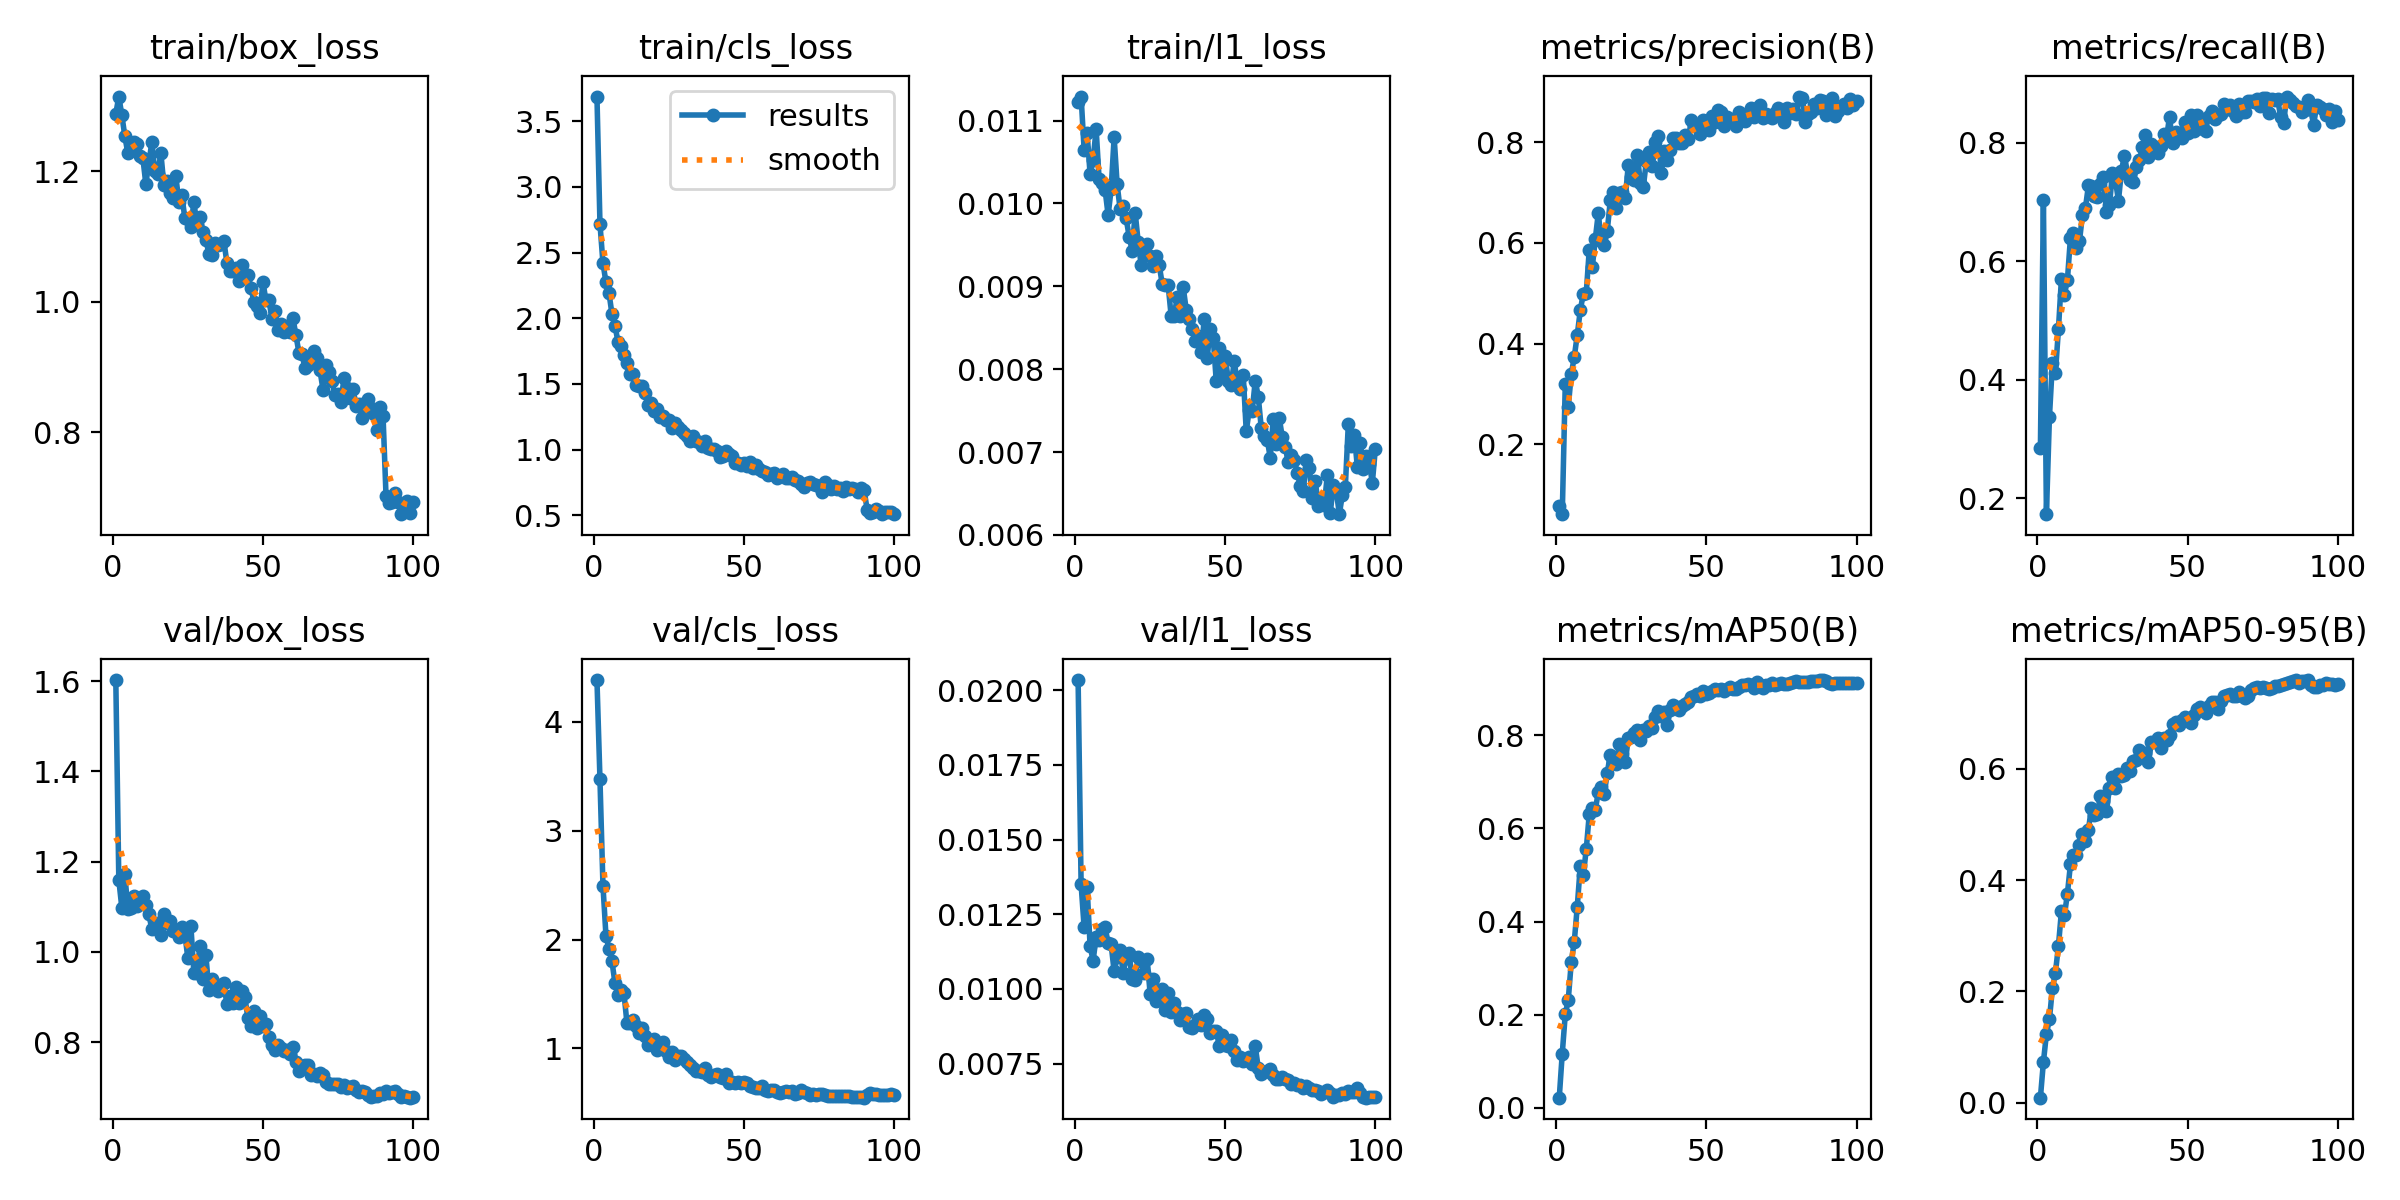

BoxPR_curve.png


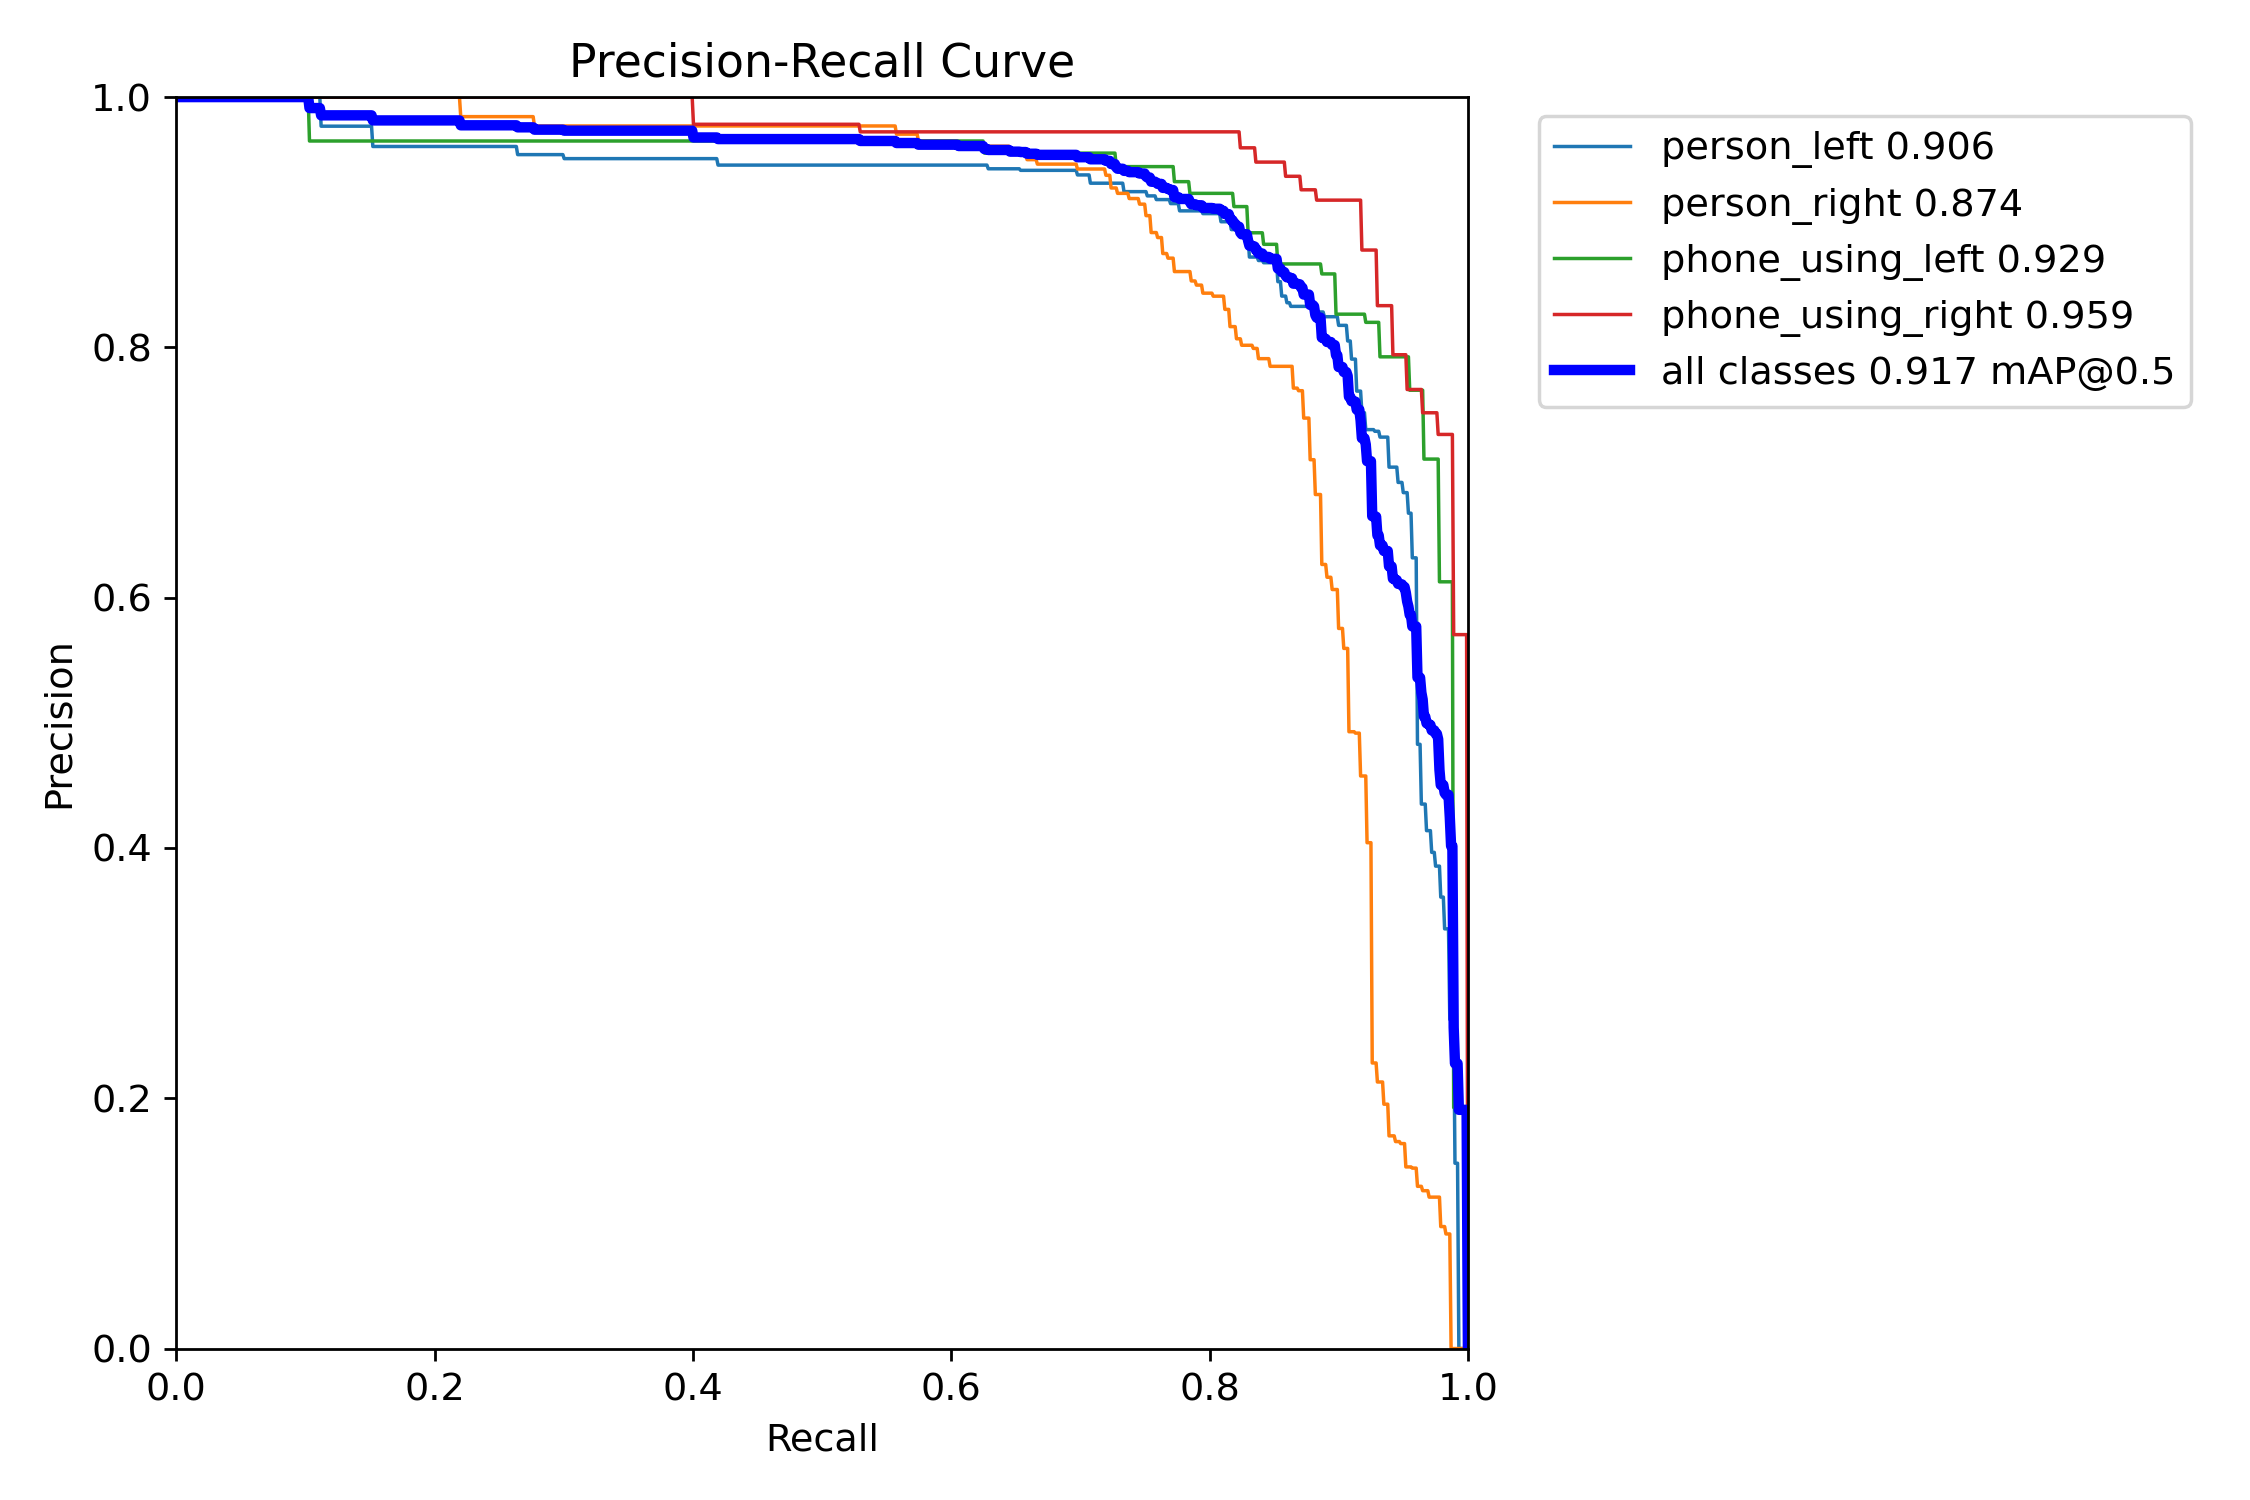

confusion_matrix.png


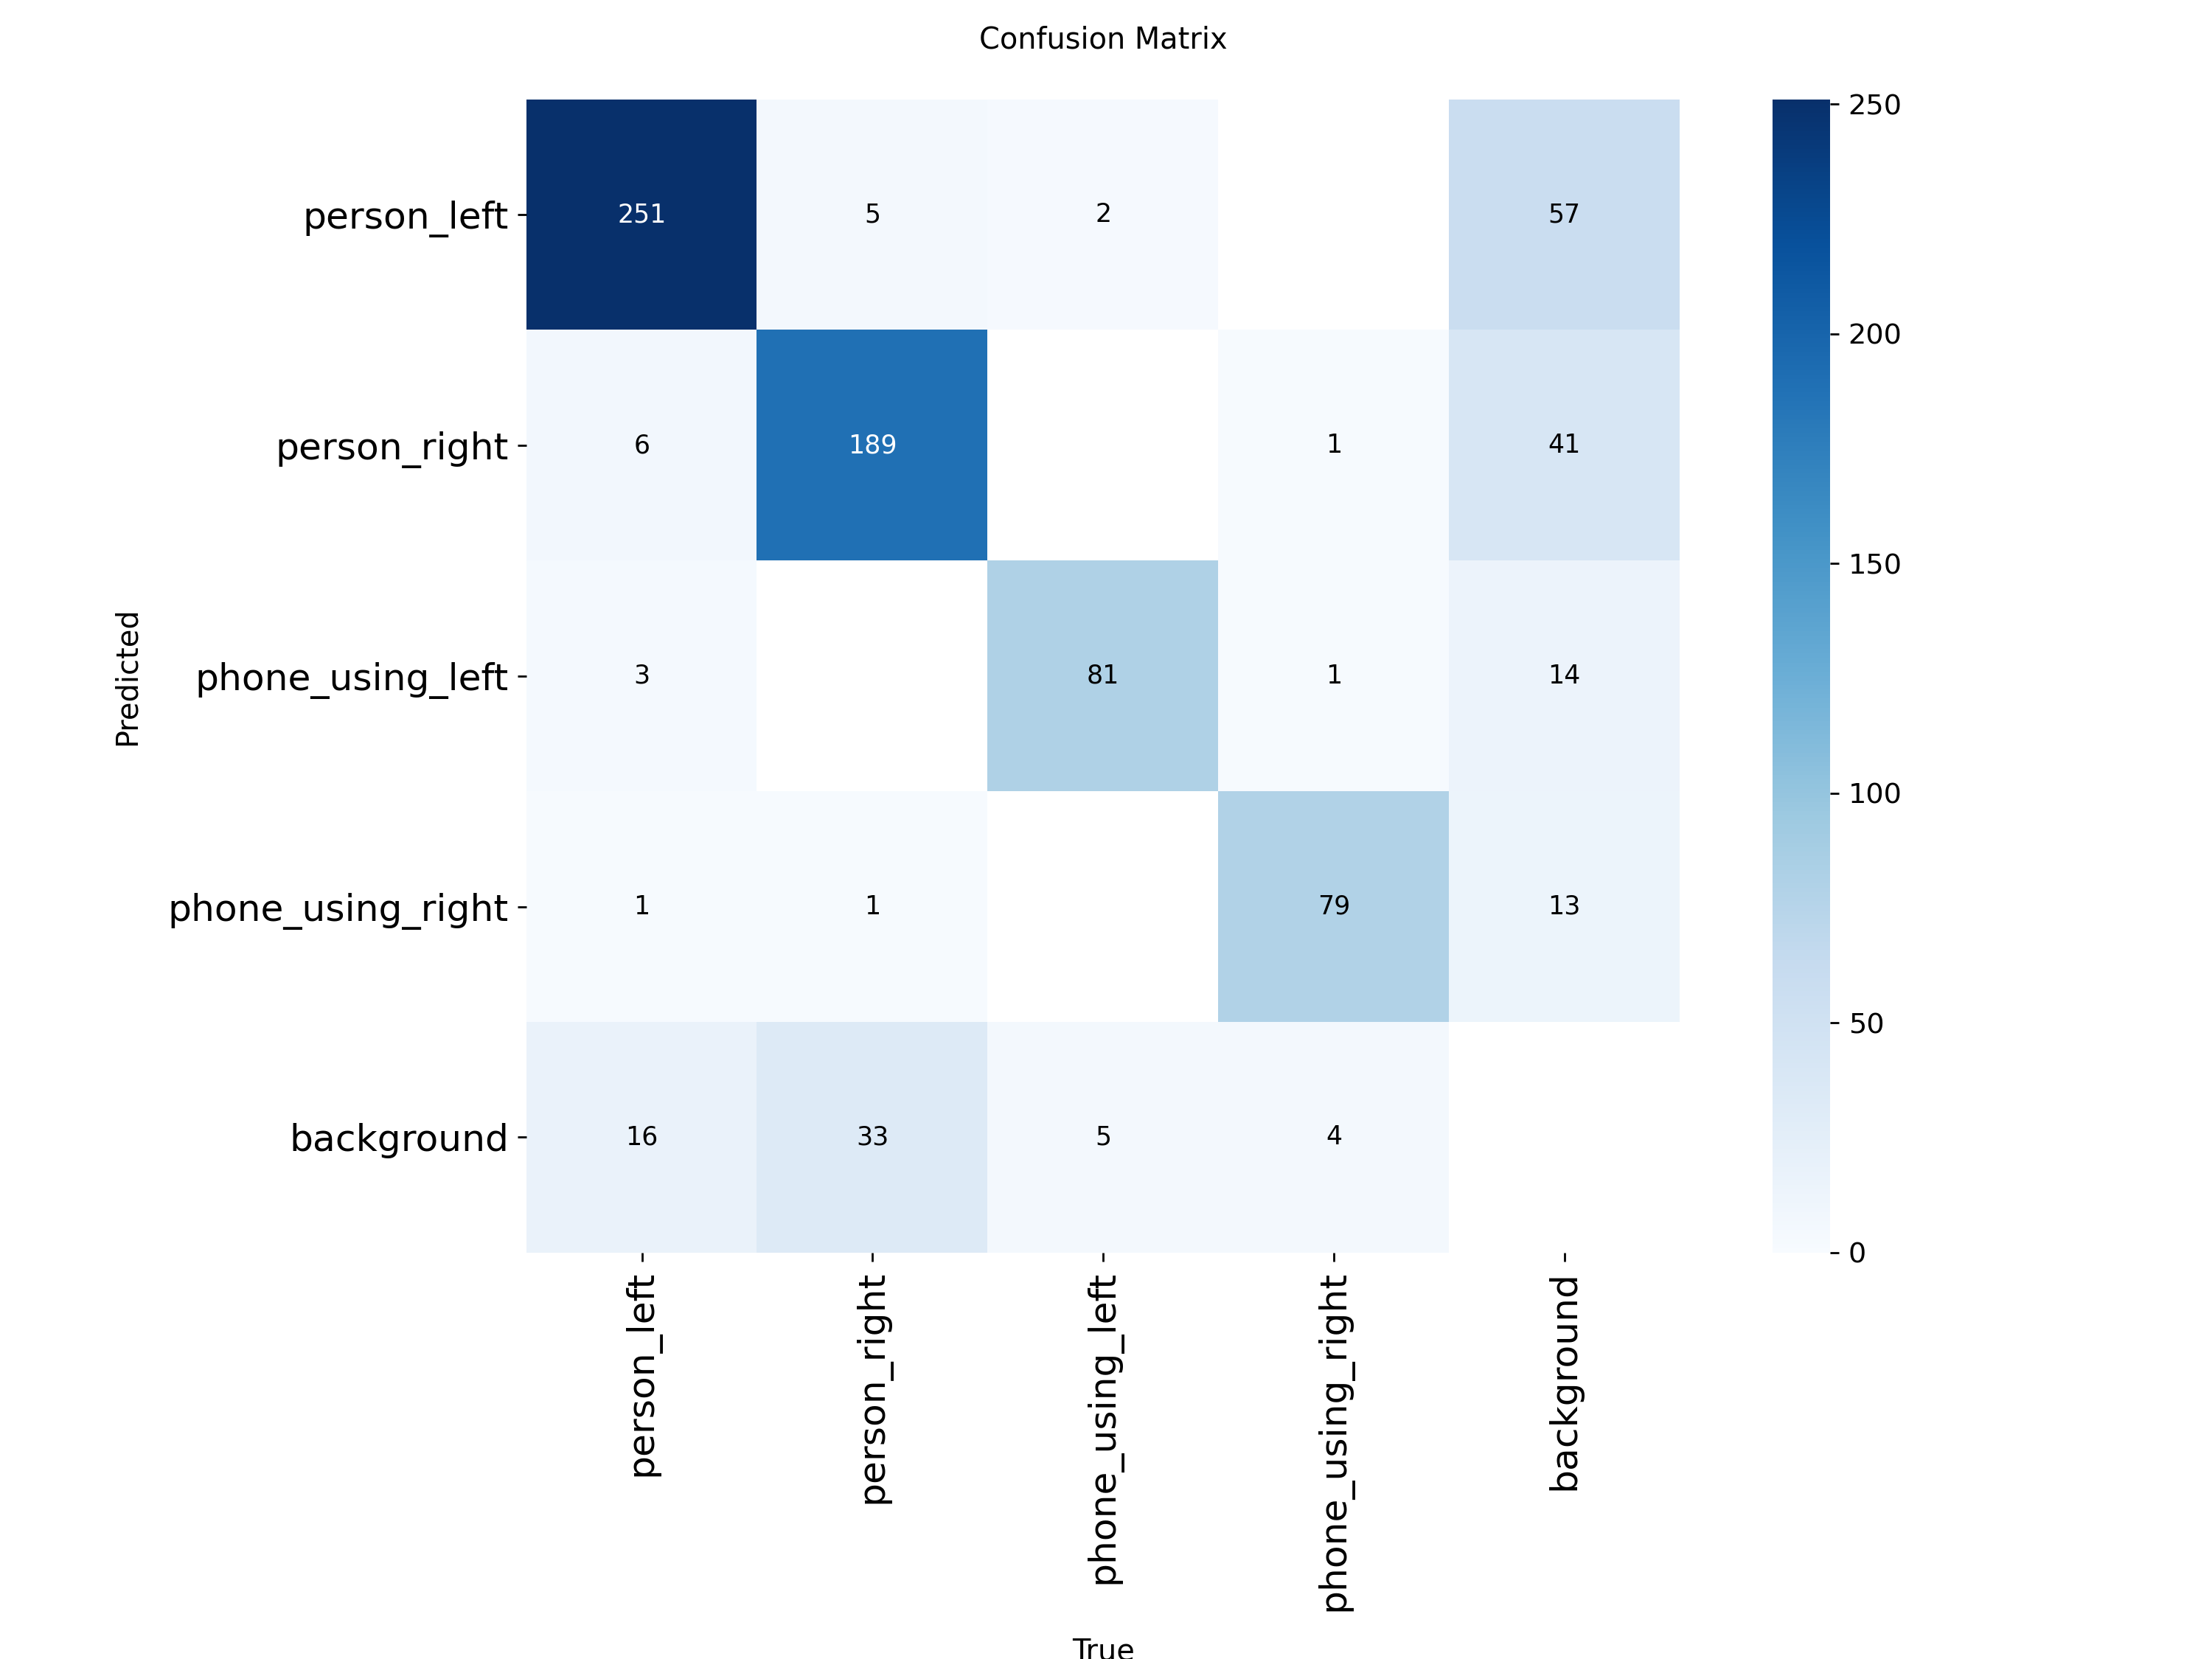

In [ ]:
from IPython.display import Image as ShowImage, display
from PIL import Image as PILImage

for name in ("results.png", "BoxPR_curve.png", "confusion_matrix.png"):
    path = os.path.join(RUN_DIR, name)
    if os.path.exists(path):
        print(name)
        display(ShowImage(filename=path, width=760))

How to read the Ultralytics plots above, together with the train vs. validation
plot from Section 5:

- **Loss curves** (`results.png`). Train loss falling while validation loss rises
  is overfitting. Both still falling at the last epoch means the run stopped
  before converging.
- **PR curve.** One line per class. A curve that keeps high precision as recall
  rises is a confident, correct class. Expect `phone` to be the lowest curve.
- **Confusion matrix.** Two cells matter most for Twist 3:
  - `person_left` vs. `person_right`: direction confusion, the baseline failure mode.
  - `phone` vs. `background`: missed phones, which means missed distracted
    pedestrians.

The CA1 report should describe what these curves show for this run, including
where the results are weak.

---

## 7. Where it got it wrong

Predictions on the held out split, side by side with the annotations, for all
three classes. Rows marked `<-- differs` are the cases to examine: a missed
person, a reversed direction, or a missed or false `phone`.

The cell after the table checks every image in the split and shows one image
that differed, picked at random, so each run of that cell shows a different error.

In [ ]:
def truth_for(image_path, class_names):
    """Read the annotated classes for one image from its label file."""
    label_path = image_path.replace(os.sep + "images" + os.sep,
                                    os.sep + "labels" + os.sep)
    label_path = os.path.splitext(label_path)[0] + ".txt"
    found = []
    if os.path.exists(label_path):
        with open(label_path, encoding="utf-8") as handle:
            for line in handle:
                if line.strip():
                    class_id = int(line.split()[0])
                    if class_id < len(class_names):
                        found.append(class_names[class_id])
    return sorted(found)


CONFIDENCE_FOR_REVIEW = 0.40

print("%-34s %-40s %s" % ("image", "annotated", "predicted"))
for path in image_paths(DATASET_DIR, EVAL_FOLDER, limit=8):
    result = trained.predict(path, conf=CONFIDENCE_FOR_REVIEW, verbose=False)[0]
    predicted = sorted(d["class_name"] for d in to_detections(result, CLASS_NAMES))
    truth = truth_for(path, CLASS_NAMES)
    flag = "  <-- differs" if predicted != truth else ""
    print("%-34s %-40s %s%s"
          % (os.path.basename(path)[:34], ", ".join(truth) or "none",
             ", ".join(predicted) or "none", flag))

image                              annotated                                predicted
2026-10-27-00-45-56_png.rf.111a527 person_left, person_left, person_left, person_left, person_left, person_left, person_left, person_right, person_right, person_right, person_right person_left, person_left, person_left, person_left, person_left, person_left, person_right, person_right, person_right, person_right, person_right  <-- differs
2026-10-27-01-02-51_jpg.rf.078f200 person_left, person_left, person_left, person_right person_left, person_left, person_left, person_right
2026-10-27-01-02-51_jpg.rf.56c49b5 person_left, person_left, person_left, person_left, person_right person_left, person_left, person_left, person_right  <-- differs
IMG_0276_jpg.rf.366d5291e557c7a388 person_left, person_left, person_right, person_right, person_right, person_right, person_right, person_right, person_right, person_right person_left, person_left, person_right, person_right, person_right, person_right, person_right, p

81 of 167 test images differ from their annotations

image     : IMG_0612_jpg.rf.809c172ad3e8bafc2619cad29aaf82f5.jpg
annotated : person_left, person_left, person_left, person_right, person_right, phone_using_right
predicted : person_left, person_left, person_left, person_right, phone_using_right, phone_using_right


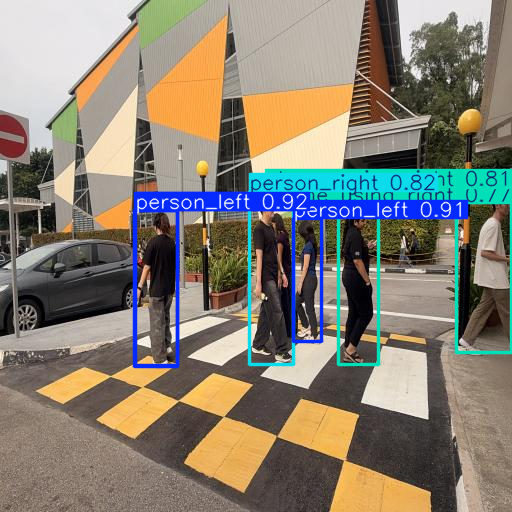

In [ ]:
# Every image in the held out split whose predicted classes differ from the
# annotations. One of them is picked at random each time this cell runs, so
# running it again shows a different error rather than the same first file.
# The picture shows whether the model missed a person, read the direction
# backwards, or missed / invented a phone. Each of those has a different fix.
from PIL import Image as PILImage
eval_images = image_paths(DATASET_DIR, EVAL_FOLDER)
differing = []
for path in eval_images:
    result = trained.predict(path, conf=CONFIDENCE_FOR_REVIEW, verbose=False)[0]
    predicted = sorted(d["class_name"] for d in to_detections(result, CLASS_NAMES))
    truth = truth_for(path, CLASS_NAMES)
    if predicted != truth:
        differing.append((path, truth, predicted))

print("%d of %d %s images differ from their annotations"
      % (len(differing), len(eval_images), EVAL_FOLDER))

if differing:
    path, truth, predicted = random.choice(differing)
    result = trained.predict(path, conf=CONFIDENCE_FOR_REVIEW, verbose=False)[0]
    print("")
    print("image     :", os.path.basename(path))
    print("annotated :", ", ".join(truth) or "none")
    print("predicted :", ", ".join(predicted) or "none")
    # result.plot() returns a BGR array. PIL wants RGB, so the channels are
    # reversed before display.
    display(PILImage.fromarray(result.plot()[:, :, ::-1]))
else:
    print("Nothing in the %s split differed." % EVAL_FOLDER)

Record the rows that differ in the CA1 report as they came out, noting for each
one whether the error was a direction error or a `phone` error.

---

## 8. Counting

The model reports boxes. The Twist 3 output is three counts per image:
`person_left`, `person_right` and `phone`. Detections below
`CONFIDENCE_THRESHOLD` are dropped before counting, and every class is always
present in the counts, including at zero.

Counts are **per image** and are never summed across images: one person
photographed ten times is ten detections of one person.

In [ ]:
# Named once, here, and used everywhere below, for all three classes. Justify the
# value in the CA1 report using the threshold table further down.
CONFIDENCE_THRESHOLD = 0.40

### Is there anything to threshold

Checks the highest confidence the model produces on the held out split. If
nothing reaches the threshold, every count will be zero and the fix is more
training, not a lower threshold.

In [ ]:
best_confidence = 0.0
for path in image_paths(DATASET_DIR, EVAL_FOLDER):
    result = trained.predict(path, conf=0.001, verbose=False)[0]
    for detection in to_detections(result, CLASS_NAMES):
        if detection["confidence"] > best_confidence:
            best_confidence = detection["confidence"]

print("highest confidence anywhere on the %s split : %.3f" % (EVAL_FOLDER, best_confidence))
print("the threshold chosen above : %.2f" % CONFIDENCE_THRESHOLD)

if best_confidence < CONFIDENCE_THRESHOLD:
    print("")
    print("Nothing reaches the threshold, so every count below will be zero.")
    print("The threshold is not the problem and lowering it is not the fix. The")
    print("model is under trained: it has learned roughly where people are and")
    print("has not learned to be sure. Go back to Section 4, raise the epochs,")
    print("and run again. The optimiser step count printed there is the number")
    print("to change.")

highest confidence anywhere on the test split : 0.993
the threshold chosen above : 0.40


In [ ]:
def count_people(model, image_path, class_names, threshold):
    """Count the detections in one image, grouped by class.

    For Twist 3 the counts hold person_left, person_right and phone.

    Args:
        model: the trained YOLO model
        image_path: path to a single image
        class_names: the ordered class list read from data.yaml
        threshold: detections below this confidence are dropped

    Returns:
        (counts, kept), where counts maps every class name to a whole number and
        kept is the list of detections that survived the threshold

    Requirement:
        Every class appears in counts, including the ones at zero. A caller
        reading the result should never have to guess whether a missing name
        means none were found or means the class does not exist.

        An image with nobody in it is a valid result of zero, not an error.
    """
    result = model.predict(image_path, conf=0.01, verbose=False)[0]
    detections = to_detections(result, class_names)

    kept = []
    for detection in detections:
        if detection["confidence"] >= threshold:
            kept.append(detection)

    counts = {}
    for name in class_names:
        counts[name] = 0
    for detection in kept:
        # .get() so an ID outside the class list (named by number in
        # to_detections) is still counted instead of raising KeyError.
        counts[detection["class_name"]] = counts.get(detection["class_name"], 0) + 1

    return counts, kept

In [ ]:
for path in image_paths(DATASET_DIR, EVAL_FOLDER, limit=4):
    counts, kept = count_people(trained, path, CLASS_NAMES, CONFIDENCE_THRESHOLD)
    print("%-34s %s" % (os.path.basename(path)[:34],
                        "  ".join("%s=%d" % (n, counts[n]) for n in CLASS_NAMES)))

2026-10-27-00-45-56_png.rf.111a527 person_left=6  person_right=5  phone_using_left=0  phone_using_right=0
2026-10-27-01-02-51_jpg.rf.078f200 person_left=3  person_right=1  phone_using_left=0  phone_using_right=0
2026-10-27-01-02-51_jpg.rf.56c49b5 person_left=3  person_right=1  phone_using_left=0  phone_using_right=0
IMG_0276_jpg.rf.366d5291e557c7a388 person_left=2  person_right=10  phone_using_left=0  phone_using_right=0


### What the threshold is doing

One image, counted at five thresholds, for all three classes. The raw
detections are printed first, and the table shows how each threshold changes
the counts.

A low threshold finds more people and phones but also invents some. A high
threshold keeps only confident detections and misses partly visible ones. Small
objects such as phones usually score lower than people, so a high threshold
tends to drop `phone` first.

In [ ]:
sample_path = image_paths(DATASET_DIR, EVAL_FOLDER, limit=1)[0]
print(os.path.basename(sample_path))
print("")

everything = to_detections(
    trained.predict(sample_path, conf=0.001, verbose=False)[0], CLASS_NAMES)
everything.sort(key=lambda detection: detection["confidence"], reverse=True)

print("every detection in this image, most confident first")
for detection in everything[:12]:
    print("   %-14s %.3f" % (detection["class_name"], detection["confidence"]))
if len(everything) > 12:
    print("   ... and %d more below these" % (len(everything) - 12))
print("")
print("%-11s %s" % ("threshold", "counts"))
for threshold in (0.15, 0.25, 0.40, 0.60, 0.80):
    counts, kept = count_people(trained, sample_path, CLASS_NAMES, threshold)
    print("%-11.2f %s  (%d detections kept)"
          % (threshold, "  ".join("%s=%d" % (n, counts[n]) for n in CLASS_NAMES),
             len(kept)))

2026-10-27-00-45-56_png.rf.111a527b64b5baece003935241a4e6b6.jpg

every detection in this image, most confident first
   person_right   0.954
   person_left    0.942
   person_right   0.933
   person_left    0.917
   person_left    0.915
   person_left    0.902
   person_left    0.859
   person_left    0.835
   person_right   0.767
   person_right   0.654
   person_right   0.580
   person_right   0.363
   ... and 47 more below these

threshold   counts
0.15        person_left=7  person_right=6  phone_using_left=0  phone_using_right=0  (13 detections kept)
0.25        person_left=7  person_right=6  phone_using_left=0  phone_using_right=0  (13 detections kept)
0.40        person_left=6  person_right=5  phone_using_left=0  phone_using_right=0  (11 detections kept)
0.60        person_left=6  person_right=4  phone_using_left=0  phone_using_right=0  (10 detections kept)
0.80        person_left=6  person_right=2  phone_using_left=0  phone_using_right=0  (8 detections kept)


A count only changes where the threshold crosses one of the confidence values
listed above it. Bunched confidences give a flat table that drops suddenly;
spread out confidences give a gradual step down.

For the CA1 report, record the chosen threshold, its effect on `phone` in
particular, and what it costs. A threshold tuned until one image matches is
tuned to that one image.

---

## 9. Export the Twist 3 artifacts

Exports `BEST_WEIGHTS` from this run to `artifacts/CA1_Twist3/best.pt`, with a
metrics summary in `artifacts/CA1_Twist3/baseline_metrics.json`, separate from
the Lesson 3 baseline in `artifacts/L3/`.

The export only replaces what is there when this run is better. The overall
mAP@0.5 from Section 6 is compared with the `mAP50` saved in
`baseline_metrics.json`. If this run scores higher, or nothing has been exported
yet, both files are updated. Otherwise the previous export is kept, so a weaker
experiment never overwrites the model Lesson 4 serves.

In [ ]:
import shutil

# Twist 3 artifacts are kept apart from the baseline in artifacts/L3.
ARTIFACT_DIR = os.path.join(PROJECT_ROOT, "artifacts", "CA1_Twist3")
ARTIFACT_WEIGHTS = os.path.join(ARTIFACT_DIR, "best.pt")
ARTIFACT_METRICS = os.path.join(ARTIFACT_DIR, "baseline_metrics.json")
os.makedirs(ARTIFACT_DIR, exist_ok=True)


def exported_map50(metrics_path):
    """The mAP50 of the model already exported, or None when there is none."""
    if not os.path.exists(metrics_path):
        return None
    with open(metrics_path, encoding="utf-8") as handle:
        saved = json.load(handle)
    if "mAP50" in saved:
        return float(saved["mAP50"])
    # Older exports stored only the per class scores. Overall mAP50 is their mean.
    scores = [row["ap50"] for row in (saved.get("per_class") or {}).values()
              if "ap50" in row]
    return sum(scores) / len(scores) if scores else None


previous_map50 = exported_map50(ARTIFACT_METRICS)
print("this run (%s) mAP@.5 : %.4f" % (TRAIN_RUN_NAME, EVAL_MAP50))
if previous_map50 is None or not os.path.exists(ARTIFACT_WEIGHTS):
    print("exported mAP@.5      : none, nothing exported yet")
    export_this_run = True
else:
    print("exported mAP@.5      : %.4f" % previous_map50)
    export_this_run = EVAL_MAP50 > previous_map50

if export_this_run:
    shutil.copy(BEST_WEIGHTS, ARTIFACT_WEIGHTS)
    with open(ARTIFACT_METRICS, "w", encoding="utf-8") as handle:
        json.dump({
            "mAP50": round(EVAL_MAP50, 4),
            "eval_split": EVAL_SPLIT,
            "classes": CLASS_NAMES,
            "per_class": PER_CLASS,
            "confidence_threshold": CONFIDENCE_THRESHOLD,
            "config": {"model_variant": MODEL_VARIANT, "epochs": EPOCHS,
                       "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE,
                       "fliplr": FLIP_LEFT_RIGHT},
            "run_name": TRAIN_RUN_NAME,
            "run_dir": RUN_DIR,
            "used_sample_data": USING_SAMPLE_DATA,
        }, handle, indent=1)
    print("")
    print("Exported: best.pt and baseline_metrics.json updated in", ARTIFACT_DIR)
else:
    print("")
    print("Not exported: %s does not beat the model already in %s."
          % (TRAIN_RUN_NAME, ARTIFACT_DIR))
    print("The previous best.pt and baseline_metrics.json are kept.")

print("Point Lesson 4 at %s to serve the Twist 3 model." % ARTIFACT_WEIGHTS)

this run (run7) mAP@.5 : 0.9302
exported mAP@.5      : 0.8526

Exported: best.pt and baseline_metrics.json updated in /content/drive/MyDrive/C389/artifacts/CA1_Twist3
Point Lesson 4 at /content/drive/MyDrive/C389/artifacts/CA1_Twist3/best.pt to serve the Twist 3 model.


### Before leaving

Checklist for the CA1 report:

- `best.pt` is on Drive under `artifacts/CA1_Twist3/` (the best run so far by
  mAP@0.5), and the baseline in `artifacts/L3/` is untouched
- The per class table (Section 6) for all three classes is copied, not estimated
- The train vs. validation plot (Section 5) is included with an overfitting /
  underfitting reading
- The confidence threshold is recorded with its reason and its effect on `phone`
- The rows that differed in Section 7 are recorded as they came out
- `fliplr=0.0` is stated with the reason it cannot be enabled

Twist 3 adds a class to the same single-frame training run. Deciding whether a
pedestrian is distracted (a `phone` box overlapping a person box) is a
post-processing step on these counts and boxes, and needs no tracking.